In [ ]:
# Paths: set DATA_DIR / OUTPUT_DIR as environment variables, or edit the defaults below.
import os
DATA_DIR = os.environ.get("DATA_DIR", "../data")


In [1]:
pass  # Colab only: from google.colab import drive
pass  # Colab only: drive.mount('/content/drive')
PROJECT_DIR = DATA_DIR + "/"

Mounted at /content/drive


In [2]:
%pip install pandas numpy geopandas osmnx shapely requests tqdm jupyter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.4/104.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 93.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.7/76.7 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.8/59.8 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 55.1 MB/s eta 0:00:00


In [3]:
import os
import requests

SAVE_DIR = DATA_DIR + "/datasets/"
os.makedirs(SAVE_DIR, exist_ok=True)

years = [2020, 2021, 2022, 2023, 2024]

for year in years:
    fname = os.path.join(SAVE_DIR, f"collisions_{year}.csv")

    if os.path.exists(fname) and os.path.getsize(fname) > 10000:
        print(f"{year} already exists ({os.path.getsize(fname)/1e6:.1f} MB)")
        continue

    url = f"https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-collision-{year}.csv"
    print(f"Downloading {year}...")
    r = requests.get(url, timeout=120)

    if r.status_code == 200 and len(r.content) > 10000:
        with open(fname, "wb") as f:
            f.write(r.content)
        print(f"Saved ({len(r.content)/1e6:.1f} MB)")
    else:
        print(f"Failed — status {r.status_code}")

Saved (17.9 MB)
Saved (19.7 MB)
Saved (20.6 MB)
Saved (20.2 MB)
Saved (19.6 MB)


In [4]:
import pandas as pd
import numpy as np
import os

SAVE_DIR = DATA_DIR + "/datasets/"
years = [2020, 2021, 2022, 2023, 2024]

frames = []
for year in years:
    path = os.path.join(SAVE_DIR, f"collisions_{year}.csv")
    temp = pd.read_csv(path)
    print(f"{year}: {len(temp):,} rows")
    frames.append(temp)

df = pd.concat(frames, ignore_index=True)
print(f"\nCombined total: {len(df):,} rows")

2020: 91,199 rows
2021: 101,087 rows
2022: 106,004 rows
2023: 104,258 rows
2024: 100,927 rows

Combined total: 503,475 rows


/tmp/ipython-input-673/3807978783.py:11: DtypeWarning: Columns (0,2) have mixed types. Specify dtype option on import or set low_memory=False.
  temp = pd.read_csv(path)


In [5]:
#1. Droping rows with missing coordinates
df = df.dropna(subset=['latitude', 'longitude'])
print(f"After dropping missing coords: {len(df):,} rows")

#2. Parsing datetime
df['datetime'] = pd.to_datetime(df['date'] + ' ' + df['time'],
                                format='%d/%m/%Y %H:%M')
df['hour']       = df['datetime'].dt.hour
df['month']      = df['datetime'].dt.month
df['day_of_week'] = df['datetime'].dt.dayofweek  # 0=Mon, 6=Sun
df['is_weekend']  = df['day_of_week'].isin([5, 6]).astype(int)
df['is_rush_hour'] = df['hour'].isin([7, 8, 9, 16, 17, 18]).astype(int)

#3. Decoding categorical columns
severity_map = {1: 'Fatal', 2: 'Serious', 3: 'Slight'}
road_type_map = {1: 'Roundabout', 2: 'One way street', 3: 'Dual carriageway',
                 6: 'Single carriageway', 7: 'Slip road', 9: 'Unknown'}
weather_map   = {1: 'Fine', 2: 'Raining', 3: 'Snowing', 4: 'Fine+High winds',
                 5: 'Raining+High winds', 6: 'Snowing+High winds',
                 7: 'Fog', 8: 'Other', 9: 'Unknown'}
light_map     = {1: 'Daylight', 4: 'Dark+Street lights lit',
                 5: 'Dark+Street lights unlit', 6: 'Dark+No street lighting',
                 7: 'Dark+Street lighting unknown'}
surface_map   = {1: 'Dry', 2: 'Wet/Damp', 3: 'Snow', 4: 'Frost/Ice',
                 5: 'Flood', 9: 'Unknown', -1: 'Unknown'}
urban_map     = {1: 'Urban', 2: 'Rural', -1: 'Unknown', 3: 'Unknown'}

df['severity_label']  = df['collision_severity'].map(severity_map)
df['road_type_label'] = df['road_type'].map(road_type_map)
df['weather_label']   = df['weather_conditions'].map(weather_map)
df['light_label']     = df['light_conditions'].map(light_map)
df['surface_label']   = df['road_surface_conditions'].map(surface_map)
df['area_label']      = df['urban_or_rural_area'].map(urban_map)

#4. Droping rows with unknown/invalid area
df = df[df['urban_or_rural_area'].isin([1, 2])]

#5. Selecting and renaming the columns we'll actually use
cols = [
    'collision_index', 'datetime', 'hour', 'month', 'day_of_week',
    'is_weekend', 'is_rush_hour', 'latitude', 'longitude',
    'collision_severity', 'severity_label',
    'speed_limit', 'road_type', 'road_type_label',
    'weather_conditions', 'weather_label',
    'light_conditions', 'light_label',
    'road_surface_conditions', 'surface_label',
    'urban_or_rural_area', 'area_label',
    'junction_detail', 'number_of_vehicles', 'number_of_casualties'
]
df = df[cols]

#6. Quick sanity check
print(f"\nFinal cleaned shape: {df.shape}")
print(f"\nSeverity distribution:\n{df['severity_label'].value_counts()}")
print(f"\nWeather distribution:\n{df['weather_label'].value_counts()}")
print(f"\nSurface distribution:\n{df['surface_label'].value_counts()}")
print(f"\nRush hour accidents: {df['is_rush_hour'].sum():,} ({df['is_rush_hour'].mean()*100:.1f}%)")
print(f"Weekend accidents:   {df['is_weekend'].sum():,} ({df['is_weekend'].mean()*100:.1f}%)")
print(f"\nDate range: {df['datetime'].min()} → {df['datetime'].max()}")
print(f"\nSample cleaned rows:")
print(df[['datetime','severity_label','speed_limit','weather_label',
          'light_label','surface_label','is_rush_hour']].head(5))

#7. Save cleaned file
df.to_csv(DATA_DIR + "/datasets/collisions_dataset_clean.csv", index=False)

After dropping missing coords: 503,410 rows

Final cleaned shape: (503407, 25)

Severity distribution:
severity_label
Slight     385957
Serious    109960
Fatal        7490
Name: count, dtype: int64

Weather distribution:
weather_label
Fine                  400904
Raining                57179
Other                  15269
Unknown                14601
Raining+High winds      5957
Fine+High winds         5156
Fog                     2295
Snowing                 1741
Snowing+High winds       292
Name: count, dtype: int64

Surface distribution:
surface_label
Dry          361238
Wet/Damp     124484
Unknown        9434
Frost/Ice      6171
Snow           1259
Flood           821
Name: count, dtype: int64

Rush hour accidents: 194,321 (38.6%)
Weekend accidents:   126,143 (25.1%)

Date range: 2020-01-01 00:01:00 → 2024-12-31 23:30:00

Sample cleaned rows:
             datetime severity_label  speed_limit weather_label  \
0 2020-06-28 04:55:00        Serious           20          Fine   
1 2020-10

#EDA

In [7]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

OUTPUT_DIR = DATA_DIR + "/figures/"
df = pd.read_csv(SAVE_DIR + "collisions_dataset_clean.csv", parse_dates=['datetime'])

/tmp/ipython-input-673/3364241807.py:5: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(SAVE_DIR + "collisions_dataset_clean.csv", parse_dates=['datetime'])


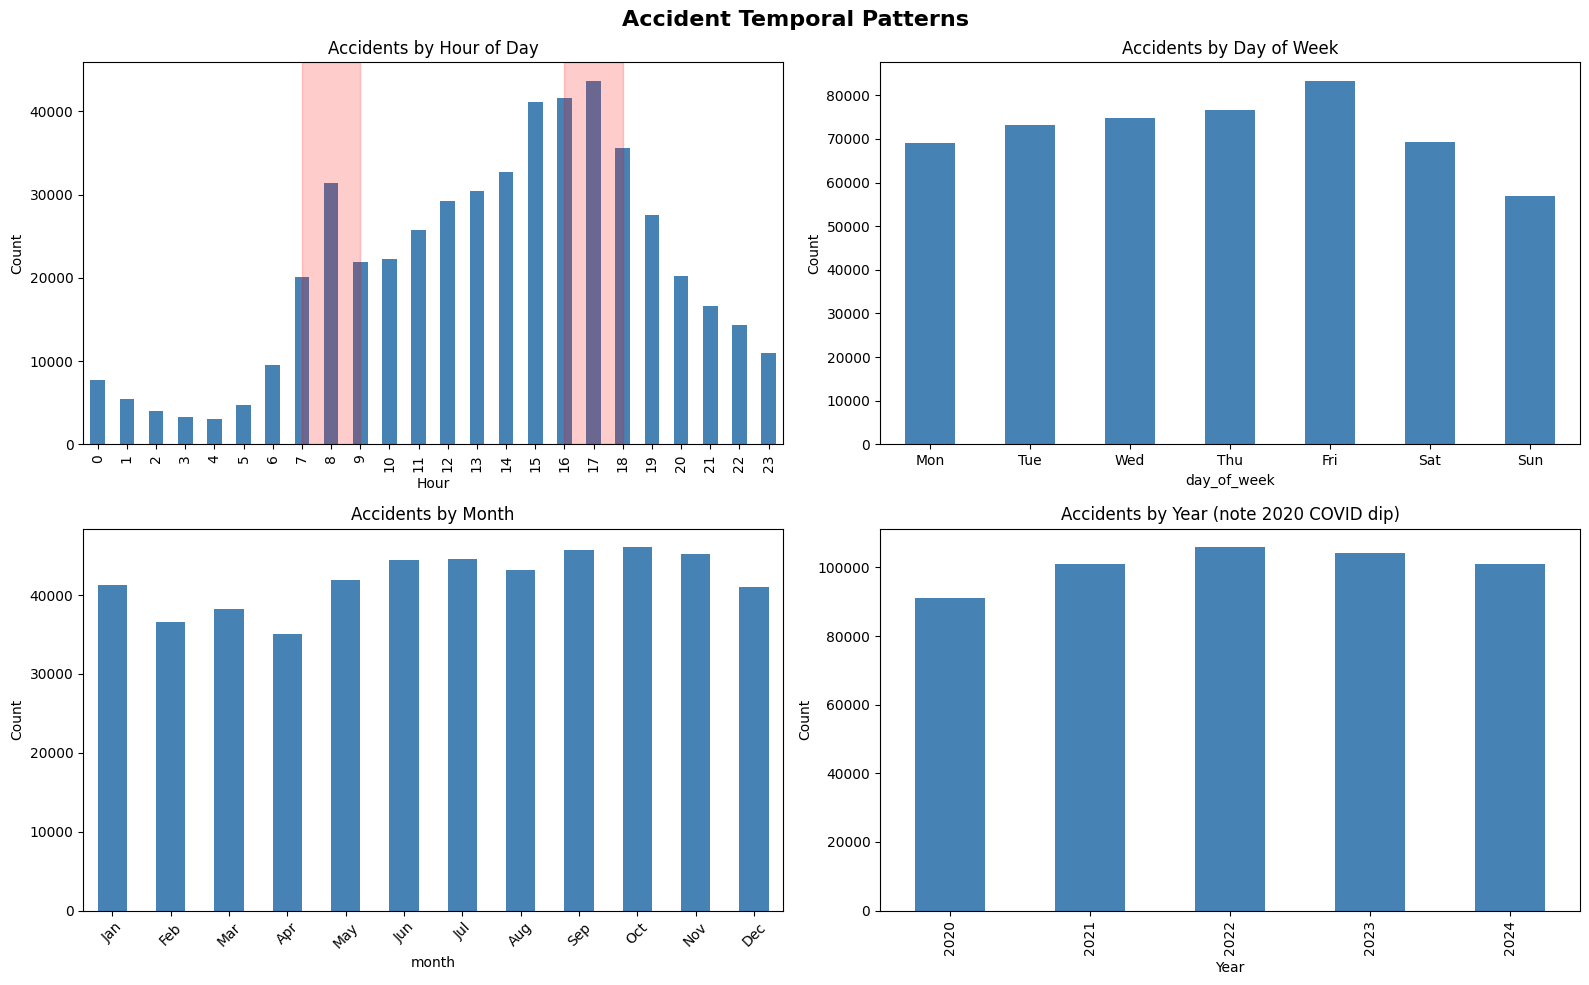

In [12]:
# FIGURE 1: Temporal Patterns
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Accident Temporal Patterns', fontsize=16, fontweight='bold')

# Accidents by hour
ax = axes[0, 0]
df['hour'].value_counts().sort_index().plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Accidents by Hour of Day')
ax.set_xlabel('Hour'); ax.set_ylabel('Count')
ax.axvspan(7, 9, alpha=0.2, color='red', label='Rush hour')
ax.axvspan(16, 18, alpha=0.2, color='red')

# Accidents by day of week
ax = axes[0, 1]
day_labels = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
df['day_of_week'].value_counts().sort_index().plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Accidents by Day of Week')
ax.set_xticklabels(day_labels, rotation=0)
ax.set_ylabel('Count')

# Accidents by month
ax = axes[1, 0]
month_labels = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
df['month'].value_counts().sort_index().plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Accidents by Month')
ax.set_xticklabels(month_labels, rotation=45)
ax.set_ylabel('Count')

# Accidents by year
ax = axes[1, 1]
df['datetime'].dt.year.value_counts().sort_index().plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Accidents by Year (note 2020 COVID dip)')
ax.set_xlabel('Year'); ax.set_ylabel('Count')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'eda_temporal.png', dpi=150, bbox_inches='tight')
plt.show()

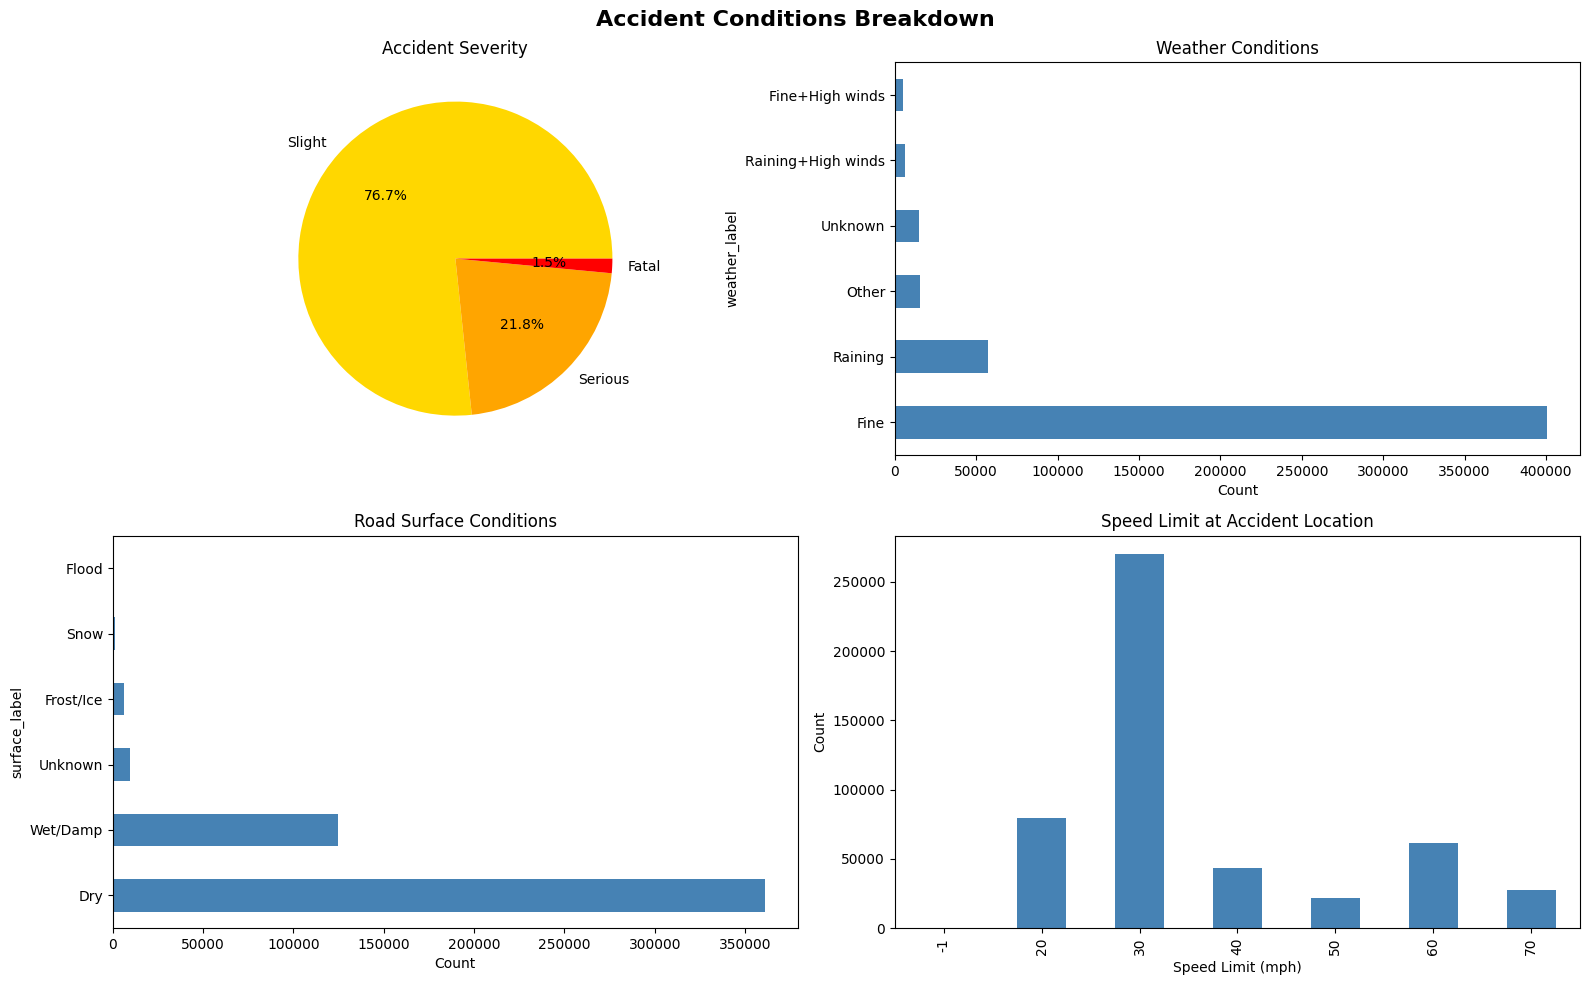

In [9]:
# FIGURE 2: Conditions Breakdown
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Accident Conditions Breakdown', fontsize=16, fontweight='bold')

# Severity
ax = axes[0, 0]
colors = {'Slight': 'gold', 'Serious': 'orange', 'Fatal': 'red'}
severity_counts = df['severity_label'].value_counts()
ax.pie(severity_counts, labels=severity_counts.index, autopct='%1.1f%%',
       colors=[colors[k] for k in severity_counts.index])
ax.set_title('Accident Severity')

# Weather
ax = axes[0, 1]
weather_counts = df['weather_label'].value_counts().head(6)
weather_counts.plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Weather Conditions')
ax.set_xlabel('Count')

# Road surface
ax = axes[1, 0]
surface_counts = df['surface_label'].value_counts()
surface_counts.plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Road Surface Conditions')
ax.set_xlabel('Count')

# Speed limit
ax = axes[1, 1]
df['speed_limit'].value_counts().sort_index().plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Speed Limit at Accident Location')
ax.set_xlabel('Speed Limit (mph)'); ax.set_ylabel('Count')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'eda_conditions.png', dpi=150, bbox_inches='tight')
plt.show()

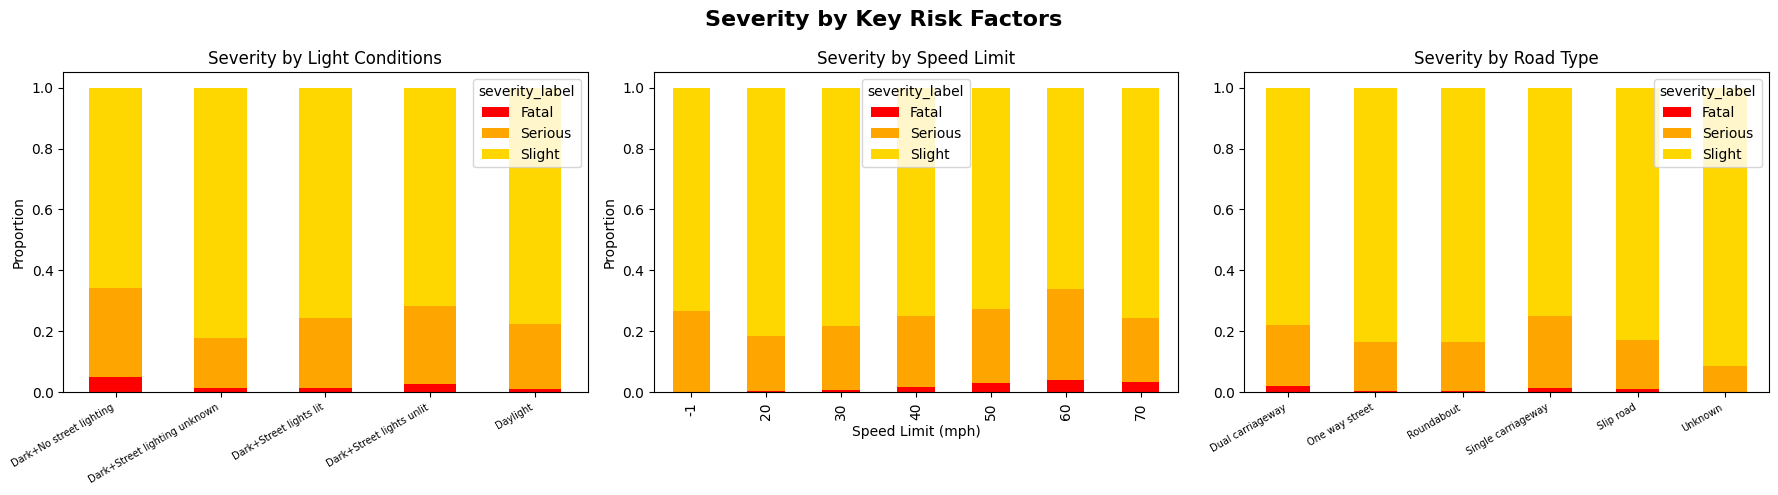

In [10]:
# FIGURE 3: Risk Factor Analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Severity by Key Risk Factors', fontsize=16, fontweight='bold')

# Severity by light conditions
ax = axes[0]
pd.crosstab(df['light_label'], df['severity_label'], normalize='index').plot(
    kind='bar', ax=ax, color=['red','orange','gold'], stacked=True)
ax.set_title('Severity by Light Conditions')
ax.set_xlabel(''); ax.set_ylabel('Proportion')
ax.tick_params(axis='x', labelsize=7)
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')

# Severity by speed limit
ax = axes[1]
pd.crosstab(df['speed_limit'], df['severity_label'], normalize='index').plot(
    kind='bar', ax=ax, color=['red','orange','gold'], stacked=True)
ax.set_title('Severity by Speed Limit')
ax.set_xlabel('Speed Limit (mph)'); ax.set_ylabel('Proportion')

# Severity by road type
ax = axes[2]
pd.crosstab(df['road_type_label'], df['severity_label'], normalize='index').plot(
    kind='bar', ax=ax, color=['red','orange','gold'], stacked=True)
ax.set_title('Severity by Road Type')
ax.set_xlabel('')
ax.tick_params(axis='x', labelsize=7)
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'eda_risk_factors.png', dpi=150, bbox_inches='tight')
plt.show()


In [11]:
# SUMMARY STATS
print("\n Key EDA Stats")
print(f"Total accidents (2020-2024):  {len(df):,}")
print(f"Fatal accidents:              {(df['severity_label']=='Fatal').sum():,} ({(df['severity_label']=='Fatal').mean()*100:.2f}%)")
print(f"Serious accidents:            {(df['severity_label']=='Serious').sum():,} ({(df['severity_label']=='Serious').mean()*100:.1f}%)")
print(f"\nTop 3 accident hours:         {df['hour'].value_counts().head(3).to_dict()}")
print(f"% in dark conditions:         {(df['light_conditions']!=1).mean()*100:.1f}%")
print(f"% on wet/icy roads:           {df['surface_label'].isin(['Wet/Damp','Frost/Ice','Snow']).mean()*100:.1f}%")
print(f"% at 30mph zones:             {(df['speed_limit']==30).mean()*100:.1f}%")


 Key EDA Stats
Total accidents (2020-2024):  503,407
Fatal accidents:              7,490 (1.49%)
Serious accidents:            109,960 (21.8%)

Top 3 accident hours:         {17: 43722, 16: 41596, 15: 41185}
% in dark conditions:         28.5%
% on wet/icy roads:           26.2%
% at 30mph zones:             53.6%
